# Quant Market-Making Assessment — Local Practice Replica

This is an **independent, unsolved practice assessment** modeled only on the public structure of the Millennium/Amplify notebook. It is not a current or proprietary assessment. The feeds are deterministic synthetic data and the simulator is local.

Work from top to bottom. Fill each `TODO`, keep the requested names and signatures, and restart the kernel before a final run. The notebook deliberately contains **112 cells**, matching the public reference notebook's length and four-part progression.

## Rules and suggested pacing

- Use ordinary Python, pandas, NumPy, and matplotlib.
- Do not change simulator source while timing an attempt.
- Treat client actions from the client's perspective; completed-trade actions are from the market maker's perspective.
- Suggested practice window: 150 minutes, followed by a separate review pass.
- Public checks give structural feedback only; they are not hidden grading logic.

In [412]:
from pathlib import Path
import sys

# Jupyter may start in the repository root, this notebook's directory, or its parent.
_candidates = []
for _base in (Path.cwd(), *Path.cwd().parents):
    _candidates.extend((_base, _base / 'millennium-market-making-prep'))
PROJECT_ROOT = next((path for path in _candidates
                     if (path / 'AmplifyQuantTrading').is_dir()), None)
if PROJECT_ROOT is None:
    raise ModuleNotFoundError('Could not locate millennium-market-making-prep; start Jupyter from the Python workspace')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from AmplifyQuantTrading import Data, Exchange, MarketMaker, HedgeFund as hf
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

hf.reset(seed=2026)
pd.set_option('display.max_columns', 10)
print('Local assessment environment ready')

Local assessment environment ready


In [413]:
# Re-run this cell whenever you want deterministic client responses.
hf.reset(seed=2026)
TICKERS = ['AAPL', 'FB', 'AMZN', 'NFLX', 'GOOGL']
ETF_TICKER = 'FAANG'

# Challenge 1 — Two-sided price making

Build a small market-making workflow: sample requests, match reference prices, create quote objects, send quotes to a simulated client, and update a market maker's inventory. A neutral quote must place its bid 2% below and its offer 2% above the reference price.

In [414]:
prices = Data.get_price_series('PricestoFeedserver')
price_requests = Data.get_price_requests('PriceRequeststoFeedserver')
print(f'{len(prices):,} price rows; {len(price_requests):,} requests')
print('First request:', price_requests[0])

6,846 price rows; 100 requests
First request: ['FB', 0, 3010]


In [415]:
print('First price:', prices[0])

First price: ['AAPL', 0, 74.7]


## Task A — Create a ten-request sample

Iterate over `price_requests` and append exactly the first ten rows to `test_requests`. Preserve order and row shape: `[ticker, date, volume]`.

In [416]:
test_requests = []

In [417]:
# TODO: append the first ten requests without modifying price_requests.
for i in range(10):
    test_requests.append(price_requests[i])

### Task A output check

Display the result. You should have ten list rows ordered by date.

In [418]:
print(test_requests)

[['FB', 0, 3010], ['AAPL', 10000, 6929], ['FB', 30000, 7015], ['FB', 70000, 4910], ['AAPL', 105000, 5783], ['AAPL', 110000, 3280], ['FB', 115000, 2465], ['AAPL', 120000, 656], ['FB', 130000, 1948], ['FB', 150000, 1386]]


### Local structural check

The cell below reports whether the required outer shape is present. It does not reveal or grade your implementation.

In [419]:
ok = (len(test_requests) == 10 and all(isinstance(row, list) and len(row) == 3 for row in test_requests))
print('Task A shape:', 'OK' if ok else 'needs work')

Task A shape: OK


## Task B — Match requests to reference prices

For every sampled request, find the row in `prices` with the same ticker and date. Build `request_with_prices` as `(request, reference_price)` tuples. Preserve sample order and reject missing or duplicate matches explicitly.

In [420]:
request_with_prices = []

In [421]:
# TODO: match by both ticker and date, then populate request_with_prices.
# Target shape: [(['AAPL', 10000, 1000], 74.63), ...]
for request in test_requests:
    count = 0
    match = None
    for price in prices:
        if request[0] == price[0] and request[1] == price[1]:
            count += 1
            match = price[2]
    if count != 1:
        raise ValueError(f'more than one price for {request}' )
    request_with_prices.append((request, match))


### Task B output check

Inspect each pair and verify that the first element is the original three-item request and the second is a positive number.

In [422]:
for item in request_with_prices:
    print(item)

(['FB', 0, 3010], 194.44)
(['AAPL', 10000, 6929], 74.63)
(['FB', 30000, 7015], 195.75)
(['FB', 70000, 4910], 193.3)
(['AAPL', 105000, 5783], 73.13)
(['AAPL', 110000, 3280], 73.83)
(['FB', 115000, 2465], 185.76)
(['AAPL', 120000, 656], 76.56)
(['FB', 130000, 1948], 191.32)
(['FB', 150000, 1386], 195.82)


### Matching check

All ten requests should be matched once. A correct key uses both ticker and date; matching only the ticker is insufficient.

In [423]:
shape_ok = (len(request_with_prices) == len(test_requests)
            and all(isinstance(item, tuple) and len(item) == 2 for item in request_with_prices))
print('Task B shape:', 'OK' if shape_ok else 'needs work')

Task B shape: OK


## Task C — Define `QuotedTrade`

Create a class with attributes `ticker`, `trade_volume`, `ref_price`, `bid_price`, `offer_price`, and `date`. Add readable `__str__` and `__repr__` methods so logs are useful.

In [424]:
import math

In [425]:
class QuotedTrade:
    def __init__(self, ticker, trade_volume, ref_price, bid_price, offer_price, date):
        # TODO: assign all six attributes and validate obvious invalid values.
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.ref_price = ref_price
        self.bid_price = bid_price
        self.offer_price = offer_price
        self.date = date
        self.__post_init__()

    def __post_init__(self):
        if not self.ticker or isinstance(self.trade_volume, bool) or not isinstance(self.trade_volume, int) or self.trade_volume <= 0:
            raise ValueError("ticker and positive integer volume required")
        if not all(math.isfinite(x) for x in (self.ref_price, self.bid_price, self.offer_price)):
            raise ValueError("prices must be finite")
        if self.ref_price <= 0 or self.bid_price <= 0 or self.bid_price > self.offer_price:
            raise ValueError("require 0 < bid <= offer and positive reference")


    def __str__(self):
        # TODO: return a concise human-readable description.
        return (
            f"{self.ticker}: {self.trade_volume} shares, "
            f"bid {self.bid_price}, offer {self.offer_price}"
        )

    def __repr__(self):
        # TODO: return a constructor-like representation.
        return (
            f"QuotedTrade(ticker={self.ticker!r}, "
            f"trade_volume={self.trade_volume!r}, "
            f"ref_price={self.ref_price!r}, "
            f"bid_price={self.bid_price!r}, "
            f"offer_price={self.offer_price!r}, "
            f"date={self.date!r})"
        )

### Quote rule

For this challenge, `SPREAD = 0.02` means **2% away on each side**, not a 2% full width: `bid = ref × 0.98`, `offer = ref × 1.02`.

In [426]:
quoted_trades = []

In [427]:
SPREAD = 0.02

# TODO: create one QuotedTrade per matched request and append it.
for request in request_with_prices:
    info, price = request
    ticker, date, volume = info[0], info[1], info[2]
    bid = price * (1 - SPREAD)
    offer = price * (1 + SPREAD)
    if bid >= price or offer <= price:
        raise ValueError("must have bid<price<offer")
    q = QuotedTrade(ticker, volume, price, bid, offer, date)
    quoted_trades.append(q)

### Task C output check

Print the quote objects. Confirm `bid_price < ref_price < offer_price` for every row.

In [428]:
print(quoted_trades)

[QuotedTrade(ticker='FB', trade_volume=3010, ref_price=194.44, bid_price=190.5512, offer_price=198.3288, date=0), QuotedTrade(ticker='AAPL', trade_volume=6929, ref_price=74.63, bid_price=73.1374, offer_price=76.12259999999999, date=10000), QuotedTrade(ticker='FB', trade_volume=7015, ref_price=195.75, bid_price=191.835, offer_price=199.665, date=30000), QuotedTrade(ticker='FB', trade_volume=4910, ref_price=193.3, bid_price=189.434, offer_price=197.16600000000003, date=70000), QuotedTrade(ticker='AAPL', trade_volume=5783, ref_price=73.13, bid_price=71.6674, offer_price=74.59259999999999, date=105000), QuotedTrade(ticker='AAPL', trade_volume=3280, ref_price=73.83, bid_price=72.3534, offer_price=75.3066, date=110000), QuotedTrade(ticker='FB', trade_volume=2465, ref_price=185.76, bid_price=182.04479999999998, offer_price=189.4752, date=115000), QuotedTrade(ticker='AAPL', trade_volume=656, ref_price=76.56, bid_price=75.0288, offer_price=78.0912, date=120000), QuotedTrade(ticker='FB', trade_v

### Quote shape check

The next cell checks only count and required attribute names.

In [429]:
required_quote_fields = ('ticker', 'trade_volume', 'ref_price', 'bid_price', 'offer_price', 'date')
quotes_ok = (len(quoted_trades) == len(request_with_prices)
             and all(all(hasattr(q, field) for field in required_quote_fields) for q in quoted_trades))
print('Task C shape:', 'OK' if quotes_ok else 'needs work')

Task C shape: OK


## Task D — Ask the hedge-fund client

Call `hf.show(quote)` once for each quote and store each returned `HfResponse` in `hf_responses`. Its `hf_action` is lower-case `buy`, `sell`, or `refuse`, from the client's viewpoint.

In [430]:
hf_responses = []

In [431]:
# TODO: submit every quote exactly once and preserve response order.
for quote in quoted_trades:
    hf_responses.append(hf.show(quote))

### Task D output check

Inspect the simulated decisions. Accepted client buys execute at your offer; accepted client sells execute at your bid.

In [432]:
print(hf_responses)

[HfResponse(ticker=FB, trade_volume=3010, trade_price=198.3288, hf_action=buy, ref_price=194.44, bid_price=190.5512, offer_price=198.3288, date=0), HfResponse(ticker=AAPL, trade_volume=6929, trade_price=76.12259999999999, hf_action=buy, ref_price=74.63, bid_price=73.1374, offer_price=76.12259999999999, date=10000), HfResponse(ticker=FB, trade_volume=7015, trade_price=199.665, hf_action=buy, ref_price=195.75, bid_price=191.835, offer_price=199.665, date=30000), HfResponse(ticker=FB, trade_volume=4910, trade_price=189.434, hf_action=sell, ref_price=193.3, bid_price=189.434, offer_price=197.16600000000003, date=70000), HfResponse(ticker=AAPL, trade_volume=5783, trade_price=71.6674, hf_action=sell, ref_price=73.13, bid_price=71.6674, offer_price=74.59259999999999, date=105000), HfResponse(ticker=AAPL, trade_volume=3280, trade_price=None, hf_action=refuse, ref_price=73.83, bid_price=72.3534, offer_price=75.3066, date=110000), HfResponse(ticker=FB, trade_volume=2465, trade_price=182.04479999

### Response shape check

Refusals have `trade_price=None`; accepted responses have a positive execution price.

In [433]:
valid_actions = {'buy', 'sell', 'refuse'}
responses_ok = (len(hf_responses) == len(quoted_trades)
                and all(r.hf_action in valid_actions for r in hf_responses))
print('Task D shape:', 'OK' if responses_ok else 'needs work')

Task D shape: OK


## Task E — Initialize the market maker

`MarketMaker.mm()` creates zero positions for the five stocks and the FAANG ETF. It also exposes `quoted_trades`, `completed_trades`, `ETF_positions`, and `current_positions`.

In [434]:
mm = MarketMaker.mm()
print(mm.current_positions)

{'FAANG': CurrentPosition(ticker=FAANG, position_volume=0, open_price=0, date=0), 'FB': CurrentPosition(ticker=FB, position_volume=0, open_price=0, date=0), 'AAPL': CurrentPosition(ticker=AAPL, position_volume=0, open_price=0, date=0), 'AMZN': CurrentPosition(ticker=AMZN, position_volume=0, open_price=0, date=0), 'NFLX': CurrentPosition(ticker=NFLX, position_volume=0, open_price=0, date=0), 'GOOGL': CurrentPosition(ticker=GOOGL, position_volume=0, open_price=0, date=0)}


## Task F — Log every quote

Pass every object in `quoted_trades` to `mm.add_quoted_trade`. Logging all quotes is part of the audit trail, whether the client later accepts or refuses.

In [435]:
# TODO: log each quote exactly once.
for quote in quoted_trades:
    mm.add_quoted_trade(quote)

### Quote-log check

The log order should equal the submission order.

In [436]:
print(mm.quoted_trades)

[QuotedTrade(ticker='FB', trade_volume=3010, ref_price=194.44, bid_price=190.5512, offer_price=198.3288, date=0), QuotedTrade(ticker='AAPL', trade_volume=6929, ref_price=74.63, bid_price=73.1374, offer_price=76.12259999999999, date=10000), QuotedTrade(ticker='FB', trade_volume=7015, ref_price=195.75, bid_price=191.835, offer_price=199.665, date=30000), QuotedTrade(ticker='FB', trade_volume=4910, ref_price=193.3, bid_price=189.434, offer_price=197.16600000000003, date=70000), QuotedTrade(ticker='AAPL', trade_volume=5783, ref_price=73.13, bid_price=71.6674, offer_price=74.59259999999999, date=105000), QuotedTrade(ticker='AAPL', trade_volume=3280, ref_price=73.83, bid_price=72.3534, offer_price=75.3066, date=110000), QuotedTrade(ticker='FB', trade_volume=2465, ref_price=185.76, bid_price=182.04479999999998, offer_price=189.4752, date=115000), QuotedTrade(ticker='AAPL', trade_volume=656, ref_price=76.56, bid_price=75.0288, offer_price=78.0912, date=120000), QuotedTrade(ticker='FB', trade_v

## Task G — Define `CompletedTrade`

Create a record with attributes `ticker`, `trade_volume`, `trade_price`, `mm_action`, `ref_price`, `bid_price`, `offer_price`, and `date`. The action is from the **market maker's** viewpoint.

In [437]:
class CompletedTrade:
    def __init__(self, ticker, trade_volume, trade_price, mm_action,
                 ref_price, bid_price, offer_price, date):
        # TODO: assign and validate all eight fields.
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.trade_price = trade_price
        self.mm_action = mm_action
        self.ref_price = ref_price
        self.bid_price = bid_price
        self.offer_price = offer_price
        self.date = date

## Task H — Record accepted trades and update inventory

Ignore refusals. If the client buys, the maker sells; if the client sells, the maker buys. Create a `CompletedTrade` with that opposite action and pass it to `mm.add_trade`.

In [438]:
# TODO: translate accepted responses into maker-side completed trades.
for response in hf_responses:
    ticker, trade_volume, trade_price, hf_action, ref_price, bid_price, offer_price, date = response.ticker, response.trade_volume, response.trade_price, response.hf_action, response.ref_price, response.bid_price, response.offer_price, response.date
    if hf_action == 'buy':
        t = CompletedTrade(ticker, trade_volume, trade_price, 'sell', ref_price, bid_price, offer_price, date)
        mm.add_trade(t)
    elif hf_action == 'sell':
        t = CompletedTrade(ticker, trade_volume, trade_price, 'buy', ref_price, bid_price, offer_price, date)
        mm.add_trade(t)




### Completed-trade output check

Inspect the execution log and current signed positions. Positive inventory is long; negative inventory is short.

In [439]:
print(mm.completed_trades)
print(mm.current_positions)

[<__main__.CompletedTrade object at 0x1118d82f0>, <__main__.CompletedTrade object at 0x111e88b90>, <__main__.CompletedTrade object at 0x111e88cd0>, <__main__.CompletedTrade object at 0x1116a08a0>, <__main__.CompletedTrade object at 0x1116a3490>, <__main__.CompletedTrade object at 0x1118ed010>, <__main__.CompletedTrade object at 0x11169c490>, <__main__.CompletedTrade object at 0x11169de10>]
{'FAANG': CurrentPosition(ticker=FAANG, position_volume=0, open_price=0, date=0), 'FB': CurrentPosition(ticker=FB, position_volume=-5984, open_price=198.033, date=150000), 'AAPL': CurrentPosition(ticker=AAPL, position_volume=-1146, open_price=76.1226, date=105000), 'AMZN': CurrentPosition(ticker=AMZN, position_volume=0, open_price=0, date=0), 'NFLX': CurrentPosition(ticker=NFLX, position_volume=0, open_price=0, date=0), 'GOOGL': CurrentPosition(ticker=GOOGL, position_volume=0, open_price=0, date=0)}


### Accounting check

Every completed trade should correspond to one non-refused response, while every submitted quote should remain in the quote log.

In [440]:
accepted_count = sum(r.hf_action != 'refuse' for r in hf_responses)
log_ok = len(mm.quoted_trades) == len(quoted_trades) and len(mm.completed_trades) == accepted_count
print('Task H logs:', 'OK' if log_ok else 'needs work')

Task H logs: OK


## Task I — Visualize one ticker's accepted quotes

For AAPL completed trades, collect dates, bids, and offers. Keep the three lists aligned.

In [441]:
bid_data = []
offer_data = []
quote_dates = []

# TODO: populate the three lists from mm.completed_trades.
for trade in mm.completed_trades:
    if trade.ticker == 'AAPL':
        bid_data.append(trade.bid_price)
        offer_data.append(trade.offer_price)
        quote_dates.append(trade.date)

### Accepted-quote data check

The three lists must have equal lengths and matching order.

In [442]:
print('bid_data:', bid_data)
print('offer_data:', offer_data)
print('quote_dates:', quote_dates)

bid_data: [73.1374, 71.6674]
offer_data: [76.12259999999999, 74.59259999999999]
quote_dates: [10000, 105000]


### Collect matching reference prices

Build `ref_data` for the same accepted AAPL dates. Avoid accidentally including refused AAPL quotes.

In [443]:
ref_data = []

# TODO: populate ref_data in exactly the same order as quote_dates.
for trade in mm.completed_trades:
    if trade.ticker == 'AAPL':
        ref_data.append(trade.ref_price)

### Reference-price check

Confirm all four plotting vectors have equal length before plotting.

In [444]:
print('ref_data:', ref_data)
print('lengths:', len(quote_dates), len(bid_data), len(offer_data), len(ref_data))

ref_data: [74.63, 73.13]
lengths: 2 2 2 2


### Plot the three price series

Use a labelled line plot with date on the x-axis and price on the y-axis. The reference line should sit between bid and offer for neutral quotes.

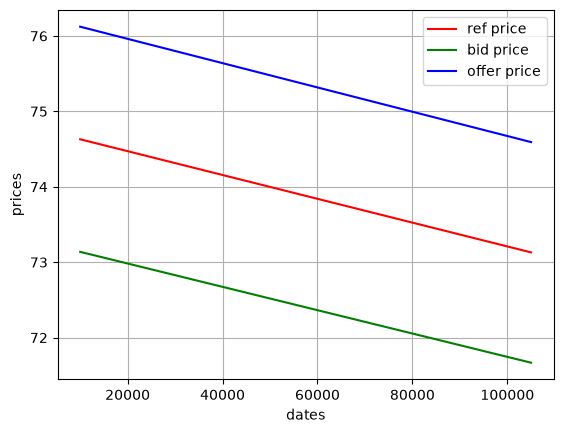

In [445]:
# TODO: plot bid_data, ref_data, and offer_data against quote_dates.
plt.plot(quote_dates, ref_data, color='red', label='ref price')
plt.plot(quote_dates, bid_data, color='green', label='bid price')
plt.plot(quote_dates, offer_data, color='blue', label='offer price')
plt.xlabel('dates')
plt.ylabel('prices')
plt.legend()
plt.grid()
plt.show()


### Challenge 1 checkpoint

Before moving on, restart and run cells 0–59 with your implementations. Check that the logs contain no duplicate quotes or executions.

In [446]:
print('quotes:', len(mm.quoted_trades), 'completed:', len(mm.completed_trades))
print('nonzero positions:', {t: p.position_volume for t, p in mm.current_positions.items() if p.position_volume})

quotes: 10 completed: 8
nonzero positions: {'FB': -5984, 'AAPL': -1146}


# Challenge 2 — Inventory-aware price skewing

Process an extended request stream. A long stock position should shift both quote sides downward to encourage a client buy and discourage another client sell. A short position should shift both sides upward.

## Skewing contract

Choose and document a deterministic rule for long, short, and flat positions. Keep `bid < offer`, keep both prices positive, and do not use future requests or prices. The public reference used piecewise shifts; your implementation may be cleaner but must follow the same economic direction.

In [447]:
# Re-importing is harmless and makes the section boundary explicit.
from AmplifyQuantTrading import Data, MarketMaker, HedgeFund as hf
hf.reset(seed=2027)

In [448]:
# Reset response state for a reproducible timed attempt.
hf.reset(seed=2027)

## Reuse your record classes

Challenge 2 uses the `QuotedTrade` and `CompletedTrade` definitions you wrote above. If you run this section alone, execute those class cells first.

In [449]:
required_classes_ready = all(name in globals() for name in ('QuotedTrade', 'CompletedTrade'))
print('Record classes ready:', required_classes_ready)

Record classes ready: True


## Task A — Full request loop

For each request: locate the matching price, inspect current inventory, calculate a skewed two-sided quote, log it, ask the client, and record any accepted trade with the opposite maker action. Track AAPL inventory over time for later inspection.

In [450]:
mm = MarketMaker.mm()
prices = Data.get_price_series('PricestoFeedserverExtended')
price_requests = Data.get_price_requests('PriceRequeststoFeedserverExtended')
print(len(prices), len(price_requests))

6846 520


In [451]:
print(mm.current_positions)

{'FAANG': CurrentPosition(ticker=FAANG, position_volume=0, open_price=0, date=0), 'FB': CurrentPosition(ticker=FB, position_volume=0, open_price=0, date=0), 'AAPL': CurrentPosition(ticker=AAPL, position_volume=0, open_price=0, date=0), 'AMZN': CurrentPosition(ticker=AMZN, position_volume=0, open_price=0, date=0), 'NFLX': CurrentPosition(ticker=NFLX, position_volume=0, open_price=0, date=0), 'GOOGL': CurrentPosition(ticker=GOOGL, position_volume=0, open_price=0, date=0)}


In [452]:
aapl_positions = []
aapl_position_dates = []

# TODO: implement the sequential inventory-aware quoting loop.
# Create an efficient lookup:
# (ticker, date) -> reference price
price_lookup = {
    (ticker, date): ref_price
    for ticker, date, ref_price in prices
}

for request in price_requests:
    ticker, date, volume = request
    key = (ticker, date)
    if key not in price_lookup:
        raise ValueError('no match')
    ref_price = price_lookup[key]

    position = mm.current_positions[ticker].position_volume
    if position > 0:
        # Long: move prices down to encourage clients to buy.
        bid_price = ref_price * 0.95
        offer_price = ref_price * 1.01

    elif position < 0:
        # Short: move prices up to encourage clients to sell.
        bid_price = ref_price * 0.99
        offer_price = ref_price * 1.05

    else:
        # Flat: neutral quote, 2% away on each side.
        bid_price = ref_price * 0.98
        offer_price = ref_price * 1.02

    # Create and log the quote.
    quoted_trade = QuotedTrade(ticker, volume, ref_price, bid_price, offer_price, date)
    mm.add_quoted_trade(quoted_trade)

    # Send the quote to the simulated client.
    response = hf.show(quoted_trade)

    if response.hf_action == "buy":
        # Client buys, so the market maker sells.
        mm_action = "sell"

    elif response.hf_action == "sell":
        # Client sells, so the market maker buys.
        mm_action = "buy"

    else:
        # Refused quote: no completed trade.
        mm_action = None

    if mm_action is not None:
        completed_trade = CompletedTrade(response.ticker, response.trade_volume, response.trade_price, mm_action, response.ref_price, response.bid_price, response.offer_price, response.date)
        mm.add_trade(completed_trade)

    # Record AAPL inventory after processing the response.
    if ticker == "AAPL":
        aapl_position_dates.append(date)
        aapl_positions.append(mm.current_positions["AAPL"].position_volume)

    

In [453]:
print('quotes logged:', len(mm.quoted_trades))
print('trades completed:', len(mm.completed_trades))
print('final positions:', mm.current_positions)

quotes logged: 520
trades completed: 404
final positions: {'FAANG': CurrentPosition(ticker=FAANG, position_volume=0, open_price=0, date=0), 'FB': CurrentPosition(ticker=FB, position_volume=-4368, open_price=220.285, date=5665000), 'AAPL': CurrentPosition(ticker=AAPL, position_volume=-55159, open_price=82.7874, date=5565000), 'AMZN': CurrentPosition(ticker=AMZN, position_volume=1648, open_price=1864.59, date=5690000), 'NFLX': CurrentPosition(ticker=NFLX, position_volume=32062, open_price=422.182, date=5660000), 'GOOGL': CurrentPosition(ticker=GOOGL, position_volume=6492, open_price=1387.97, date=5675000)}


## Task B — Visualize skewed AAPL quotes

Extract AAPL date, bid, reference, and offer series from `mm.quoted_trades`. Plot them together and explain where inventory caused an asymmetric center shift.

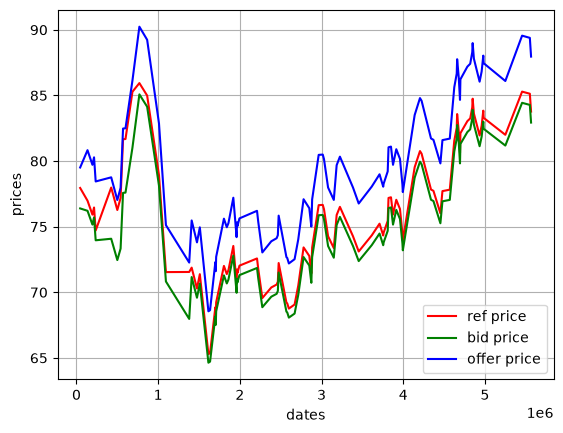

In [454]:
# TODO: build aligned AAPL series and plot them.
aapl_date=[]
aapl_ref=[]
aapl_bid=[]
aapl_offer=[]
for trade in mm.quoted_trades:
    if trade.ticker == 'AAPL':
        aapl_date.append(trade.date)
        aapl_ref.append(trade.ref_price)
        aapl_bid.append(trade.bid_price)
        aapl_offer.append(trade.offer_price)

plt.plot(aapl_date, aapl_ref, color='red', label='ref price')
plt.plot(aapl_date, aapl_bid, color='green', label='bid price')
plt.plot(aapl_date, aapl_offer, color='blue', label='offer price')
plt.xlabel('dates')
plt.ylabel('prices')
plt.legend()
plt.grid()
plt.show()


# Research interlude — Beta and hedging

Estimate each component stock's beta to the FAANG ETF using aligned simple returns. These estimates will be inputs to Challenge 3.

## Beta definition

For stock return series $R_i$ and ETF returns $R_m$, compute

$$\beta_i = \frac{\operatorname{Cov}(R_i, R_m)}{\operatorname{Var}(R_m)}.$$

Use one consistent return convention, drop only the initial missing row, and verify that the ETF variance is positive.

In [455]:
import pandas as pd
prices_long = Data.get_price_series('PricestoFeedserverEtfUpdate')

## Equal-weight ETF construction

The five components can be rebased to 100 at the first date. Their row-wise mean is a synthetic equal-weight basket. The supplied FAANG series is a tradable ETF with temporary deviations from that basket.

In [456]:
prices_long = Data.get_price_series('PricestoFeedserverEtfUpdate')

In [457]:
print(prices_long[:5])

[['AAPL', 0, 74.7], ['AMZN', 0, 1953.0], ['FAANG', 0, 100.0], ['FB', 0, 196.44], ['GOOGL', 0, 1386.0]]


In [458]:
# TODO: reshape prices_long or split it by ticker, sort by date,
# and calculate aligned simple-return Series for all six assets.
prices_df = pd.DataFrame(prices_long, columns=["ticker", "date", "price"])
prices_df = prices_df.pivot(columns = "ticker", index = "date", values = "price").sort_index()
returns = prices_df.pct_change().dropna()

AAPL_returns = returns['AAPL']
FB_returns = returns['FB']
GOOGL_returns = returns['GOOGL']
AMZN_returns = returns['AMZN']
NFLX_returns = returns['NFLX']

FAANG_returns = returns['FAANG']

In [459]:
betas = {}

# TODO: calculate each component beta to FAANG and populate betas.
faang_var = FAANG_returns.var()
if faang_var == 0:
    raise ValueError('wrong value')
betas['AAPL'] = AAPL_returns.cov(FAANG_returns) / faang_var
betas['FB'] = FB_returns.cov(FAANG_returns) / faang_var
betas['AMZN'] = AMZN_returns.cov(FAANG_returns) / faang_var
betas['GOOGL'] = GOOGL_returns.cov(FAANG_returns) / faang_var
betas['NFLX'] = NFLX_returns.cov(FAANG_returns) / faang_var

print(betas)

{'AAPL': np.float64(0.7231130235019998), 'FB': np.float64(0.847397901959469), 'AMZN': np.float64(0.7671657939278), 'GOOGL': np.float64(1.052133708454778), 'NFLX': np.float64(0.8515974540822391)}


# Challenge 3 — Beta-adjusted ETF hedging

Extend Challenge 2. After every accepted stock trade, calculate its beta-weighted dollar exposure and execute an opposing FAANG hedge through the local exchange.

## Hedging tools and sign convention

Create `ExchangeTrade(ticker, trade_volume, ref_price, action, date)`. `Exchange.execute` returns an executed trade; `mm.update_ETF_position` records it. A maker stock buy creates positive exposure and therefore needs an ETF sell. A maker stock sell needs an ETF buy.

In [460]:
mm = MarketMaker.mm()
prices = Data.get_price_series('PricestoFeedserverEtfUpdate', True)
price_requests = Data.get_price_requests('PriceRequeststoFeedserverExtended')
hf.reset(seed=2028)

In [461]:
class ExchangeTrade:
    def __init__(self, ticker, trade_volume, ref_price, action, date):
        # TODO: assign and validate the five exchange-order fields.
        self.ticker = ticker
        self.trade_volume = trade_volume
        self.ref_price = ref_price
        self.action = action
        self.date = date
        

In [462]:
print(prices.head())

        AAPL     AMZN   FAANG      FB    GOOGL    NFLX
date                                                  
0      74.70  1953.00  100.00  196.44  1386.00  381.05
5000   74.04  1943.96   99.58  197.35  1376.61  381.11
10000  74.42  1935.27  100.06  197.76  1381.43  383.00
15000  75.27  1939.40  100.52  196.64  1400.90  382.86
20000  75.34  1971.73  100.90  198.90  1412.23  382.71


In [463]:
net_exposure = []
etf_position_history = []
exposure_dates = []

# TODO: run the quote/response loop, execute one beta hedge after each fill,
# and record beta-adjusted net exposure after every request.
for request in price_requests:
    ticker, date, volume = request

    if date not in prices.index or ticker not in prices.columns:
        raise ValueError(f'No price for {ticker} at {date}')

    ref_price = float(prices.loc[date, ticker])
    position = mm.current_positions[ticker].position_volume

    # Use the same inventory-skewing rules as Challenge 2.
    if position > 0:
        bid_price = ref_price * 0.95
        offer_price = ref_price * 1.01
    elif position < 0:
        bid_price = ref_price * 0.99
        offer_price = ref_price * 1.05
    else:
        bid_price = ref_price * 0.98
        offer_price = ref_price * 1.02

    quoted_trade = QuotedTrade(
        ticker, volume, ref_price, bid_price, offer_price, date
    )
    mm.add_quoted_trade(quoted_trade)
    response = hf.show(quoted_trade)

    if response.hf_action == 'buy':
        # The client buys, so the market maker sells.
        mm_action = 'sell'
    elif response.hf_action == 'sell':
        # The client sells, so the market maker buys.
        mm_action = 'buy'
    else:
        mm_action = None

    if mm_action is not None:
        completed_trade = CompletedTrade(
            response.ticker,
            response.trade_volume,
            response.trade_price,
            mm_action,
            response.ref_price,
            response.bid_price,
            response.offer_price,
            response.date,
        )
        mm.add_trade(completed_trade)

        # Hedge the beta-adjusted dollar risk created by this fill.
        stock_direction = 1 if mm_action == 'buy' else -1
        signed_stock_risk = (stock_direction * response.trade_volume * response.trade_price * betas[ticker])

        etf_price = float(prices.loc[date, ETF_TICKER])
        required_etf_risk = -signed_stock_risk
        hedge_action = 'buy' if required_etf_risk > 0 else 'sell'
        hedge_volume = abs(required_etf_risk) / etf_price

        hedge_order = ExchangeTrade(
            ETF_TICKER, hedge_volume, etf_price, hedge_action, date
        )
        executed_hedge = Exchange.execute(hedge_order)
        mm.update_ETF_position(executed_hedge)

    # Measure the whole book after every request, including refusals.
    stock_exposure = 0.0
    for stock_ticker in TICKERS:
        stock_position = mm.current_positions[stock_ticker].position_volume
        stock_price = float(prices.loc[date, stock_ticker])
        stock_exposure += (
            stock_position * stock_price * betas[stock_ticker]
        )

    etf_position = mm.current_positions[ETF_TICKER].position_volume
    etf_price = float(prices.loc[date, ETF_TICKER])
    total_exposure = stock_exposure + etf_position * etf_price

    exposure_dates.append(date)
    net_exposure.append(total_exposure)
    etf_position_history.append(etf_position)

In [464]:
hedge_log_ok = len(mm.ETF_positions) <= len(mm.completed_trades)
print('Hedge log structurally plausible:', hedge_log_ok)
print('Final positions:', mm.current_positions)

Hedge log structurally plausible: True
Final positions: {'FAANG': CurrentPosition(ticker=FAANG, position_volume=694673, open_price=107.319, date=5690000), 'FB': CurrentPosition(ticker=FB, position_volume=9773, open_price=206.751, date=5665000), 'AAPL': CurrentPosition(ticker=AAPL, position_volume=-18538, open_price=86.7269, date=5565000), 'AMZN': CurrentPosition(ticker=AMZN, position_volume=5066, open_price=1774.57, date=5690000), 'NFLX': CurrentPosition(ticker=NFLX, position_volume=953, open_price=405.561, date=5660000), 'GOOGL': CurrentPosition(ticker=GOOGL, position_volume=-32923, open_price=1566.98, date=5605000)}


## Task B — Plot beta-adjusted net exposure

Plot `net_exposure` against `exposure_dates`, add a horizontal zero line, axis labels, and a title. Discuss large residual jumps rather than assuming the hedge is perfect.

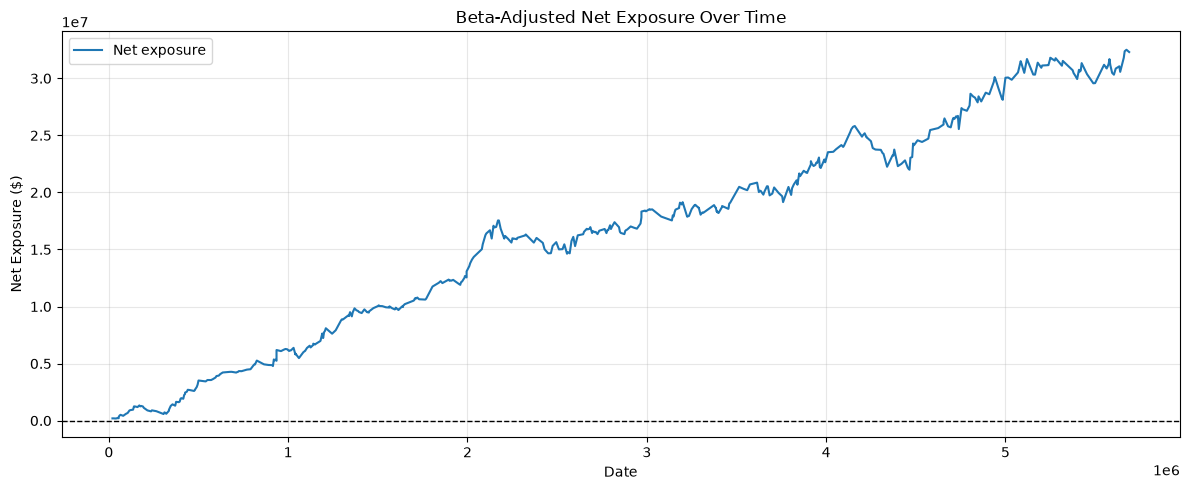

In [465]:
# TODO: plot beta-adjusted net exposure through time.
plt.figure(figsize=(12, 5))

plt.plot(
    exposure_dates,
    net_exposure,
    label="Net exposure",
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1,
    linestyle="--",
)

plt.title("Beta-Adjusted Net Exposure Over Time")
plt.xlabel("Date")
plt.ylabel("Net Exposure ($)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

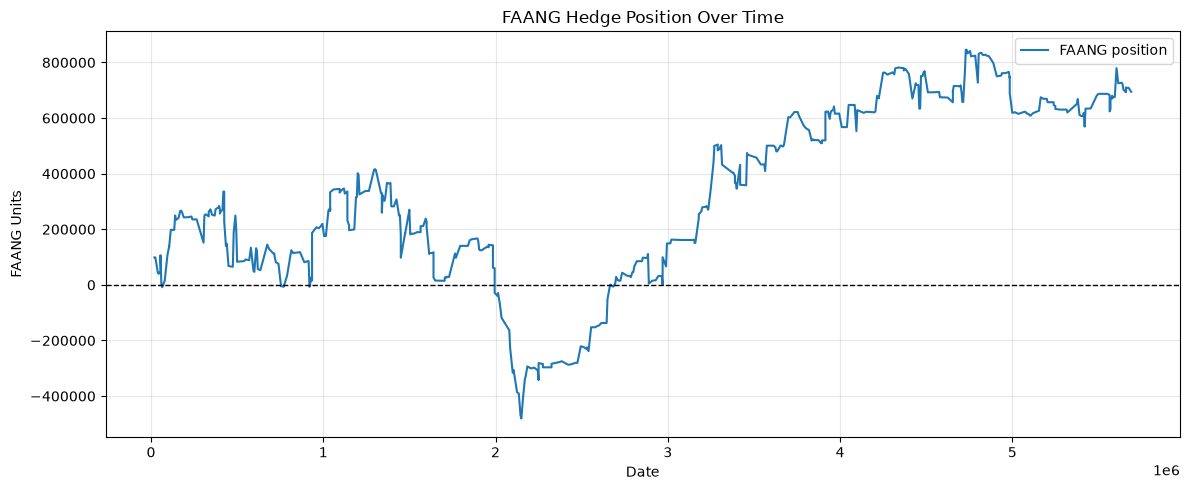

In [466]:
# TODO: plot FAANG position units through time.
plt.figure(figsize=(12, 5))

plt.plot(
    exposure_dates,
    etf_position_history,
    label="FAANG position",
)

plt.axhline(
    y=0,
    color="black",
    linewidth=1,
    linestyle="--",
)

plt.title("FAANG Hedge Position Over Time")
plt.xlabel("Date")
plt.ylabel("FAANG Units")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Risk interpretation

Beta hedging targets common-factor sensitivity, not spread risk, idiosyncratic moves, discrete-share rounding, execution costs, or model error.

In [467]:
# TODO: calculate and print mean absolute and maximum absolute net exposure.
meanabs_exposure = np.mean(np.abs(net_exposure))
maxabs_exposure = np.max(np.abs(net_exposure))
print(meanabs_exposure, maxabs_exposure)

16063220.016686525 32502623.06500896


### Challenge 3 reflection

Write three short observations: when exposure is largest, whether hedge direction is correct, and which modeling assumption most limits the result.

# Research interlude — Real versus synthetic ETF

Construct the equal-weight synthetic basket and study `real FAANG − synthetic FAANG`. A stationary-looking spread may indicate relative-value opportunities, but visual convergence alone is not proof of arbitrage.

## Research task

Split the long price records into six aligned series, rebase each component to 100, average the five rebased components, and calculate the real-minus-synthetic spread. Summarize its distribution and inspect it through time.

In [468]:
prices_long = Data.get_price_series('PricestoFeedserverEtfUpdate')

In [469]:
# TODO: create aligned AAPL, FB, AMZN, NFLX, GOOGL, and FAANG Series.
prices_df = pd.DataFrame(prices_long, columns=["ticker", "date", "price"])
prices_df = prices_df.pivot(columns = "ticker", index = "date", values = "price").sort_index()

AAPL_df = prices_df['AAPL']
FB_df = prices_df['FB']
GOOGL_df = prices_df['GOOGL']
AMZN_df = prices_df['AMZN']
NFLX_df = prices_df['NFLX']
FAANG_df = prices_df['FAANG']

AAPL_rb = 100 * AAPL_df / AAPL_df.iloc[0]
FB_rb = 100 * FB_df / FB_df.iloc[0]
GOOGL_rb = 100 * GOOGL_df / GOOGL_df.iloc[0]
AMZN_rb = 100 * AMZN_df / AMZN_df.iloc[0]
NFLX_rb = 100 * NFLX_df / NFLX_df.iloc[0]
FAANG_rb = 100 * FAANG_df / FAANG_df.iloc[0]



In [470]:
# TODO: build synthetic_faang and spread = real_faang - synthetic_faang.
syn_faang = (AAPL_rb + FB_rb + GOOGL_rb + AMZN_rb + NFLX_rb) / 5
spread = FAANG_rb - syn_faang

In [471]:
# TODO: print descriptive spread statistics and note possible outliers.
print(spread.describe())
print(spread.abs().nlargest(5))

count    1141.000000
mean        0.053785
std         1.009724
min        -3.289607
25%        -0.663740
50%         0.019406
75%         0.763105
max         2.826547
dtype: float64
date
4740000    3.289607
1050000    3.131171
1060000    2.967930
4945000    2.826547
4940000    2.811313
dtype: float64


## Research visualization

Use one figure for real versus synthetic prices and another for the spread. Include labels, legends, and a zero line on the spread chart.

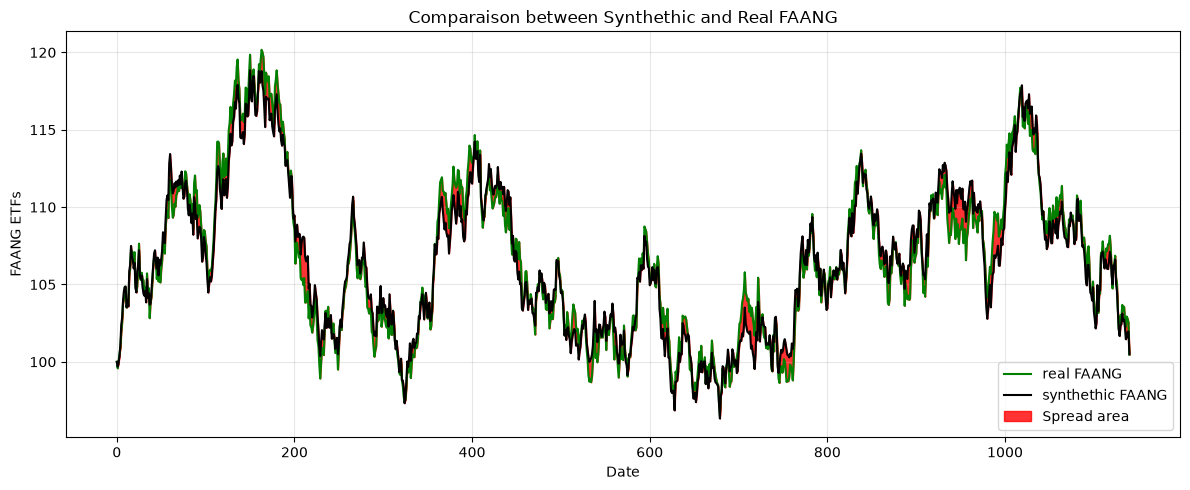

In [472]:
# TODO: plot real_faang and synthetic_faang together.
plt.figure(figsize=(12, 5))
times = np.arange(0, len(syn_faang), 1)
plt.plot(times, FAANG_rb, color="green", label="real FAANG")
plt.plot(times, syn_faang, color="black", label="synthethic FAANG")
plt.fill_between(times, FAANG_rb, syn_faang, color="red", alpha=0.8, label="Spread area")

plt.title("Comparaison between Synthethic and Real FAANG")
plt.xlabel("Date")
plt.ylabel("FAANG ETFs")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

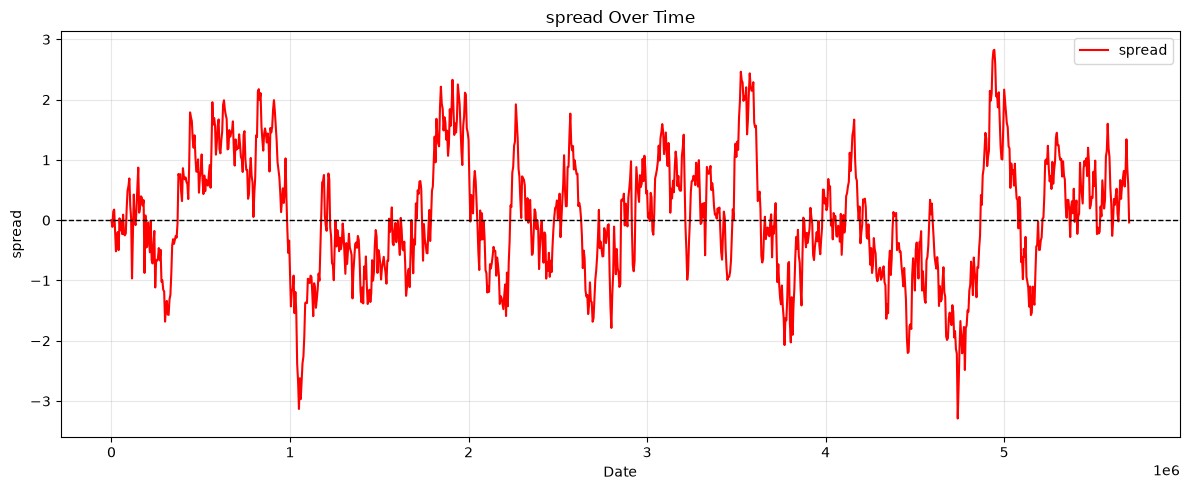

In [473]:
# TODO: plot the spread with a horizontal zero line.
plt.figure(figsize=(12, 5))

plt.plot(spread, color="red", label="spread")

plt.axhline(
    y=0,
    color="black",
    linewidth=1,
    linestyle="--",
)

plt.title("spread Over Time")
plt.xlabel("Date")
plt.ylabel("spread")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Challenge 4 — ETF/component arbitrage

Build a stateful relative-value strategy using the commission-aware hedge-fund account. Open a six-leg position only when the expected edge exceeds round-trip costs, avoid stacking uncontrolled positions, and close all legs when the spread converges or at the final date.

In [474]:
from AmplifyQuantTrading import Data
from AmplifyArbitrageTrading import HedgeFund as ArbitrageHedgeFund

prices = Data.get_price_series('PricestoFeedserverEtfUpdate', True)

In [475]:
hedge_fund = ArbitrageHedgeFund.hf(
    commission_percentage=0.001,
    data=prices,
)

In [476]:
print(prices.head())

        AAPL     AMZN   FAANG      FB    GOOGL    NFLX
date                                                  
0      74.70  1953.00  100.00  196.44  1386.00  381.05
5000   74.04  1943.96   99.58  197.35  1376.61  381.11
10000  74.42  1935.27  100.06  197.76  1381.43  383.00
15000  75.27  1939.40  100.52  196.64  1400.90  382.86
20000  75.34  1971.73  100.90  198.90  1412.23  382.71


In [477]:
# TODO: implement entry, sizing, state tracking, exit, and final liquidation.
# Use hedge_fund.execute_order(ticker, volume, action, date) for every leg.
real_faang = prices['FAANG']
synthetic_faang = sum(20 * prices[ticker] / prices[ticker].iloc[0] for ticker in TICKERS)
spread = real_faang - synthetic_faang

pair_units = 100.0
component_volumes = {ticker: pair_units * 20 /prices[ticker].iloc[0] for ticker in TICKERS}

# None, 'short_real', or 'long_real'.
position = None
positions_opened = 0

def trade_pair(real_action, component_action, date):
    hedge_fund.execute_order(
        'FAANG', pair_units, real_action, date
    )
    for ticker in TICKERS:
        hedge_fund.execute_order(
            ticker,
            component_volumes[ticker],
            component_action,
            date,
        )

for date in prices.index:
    spread_value = float(spread.loc[date])
    real_price = float(real_faang.loc[date])
    synthetic_price = float(synthetic_faang.loc[date])

    # Estimated commission for entering and exiting both sides.
    threshold = (2 * hedge_fund.commission_percentage * (real_price + synthetic_price))
    
    if position is None:
        if spread_value > threshold:
            # Real ETF is expensive.
            trade_pair('sell', 'buy', date)
            position = 'short_real'
            positions_opened += 1
        elif spread_value < -threshold:
            # Real ETF is cheap.
            trade_pair('buy', 'sell', date)
            position = 'long_real'
            positions_opened += 1
    elif position == 'short_real' and spread_value <= 0:
        trade_pair('buy', 'sell', date)
        position = None
    elif position == 'long_real' and spread_value >= 0:
        trade_pair('sell', 'buy', date)
        position = None

# Close any position still open at the final date.
if position is not None:
    final_date = prices.index[-1]
    if position == 'short_real':
        trade_pair('buy', 'sell', final_date)
    else:
        trade_pair('sell', 'buy', final_date)
    position = None

print('Positions opened:', positions_opened)
print('Ending balance:', hedge_fund.balance)

Positions opened: 57
Ending balance: 20002380.51855074


In [478]:
# TODO: calculate total realized P&L net of commissions and print ending balance.
gross_pnl = sum(
    position.profit_loss
    for position in hedge_fund.current_positions.values()
)

total_commissions = sum(
    position.commission_costs
    for position in hedge_fund.current_positions.values()
)

net_pnl = gross_pnl - total_commissions

print(f"Gross realized P&L: ${gross_pnl:,.2f}")
print(f"Total commissions:  ${total_commissions:,.2f}")
print(f"Net P&L:            ${net_pnl:,.2f}")
print(f"Ending balance:     ${hedge_fund.balance:,.2f}")

Gross realized P&L: $4,768.22
Total commissions:  $2,387.70
Net P&L:            $2,380.52
Ending balance:     $20,002,380.52


In [479]:
# TODO: choose one ticker and display its trade_history as a DataFrame.
ticker = 'AAPL'
trade_history = hedge_fund.current_positions[ticker].trade_history
aapl_history_df = pd.DataFrame(trade_history)
aapl_history_df

,action,price,volume,commission,date
0,SELL,76.11,26.773762,2.037751,25000
1,BUY,77.95,26.773762,2.087015,45000
2,BUY,78.33,26.773762,2.097189,90000
3,SELL,78.36,26.773762,2.097992,115000
4,BUY,76.02,26.773762,2.035341,145000
...,...,...,...,...,...
109,SELL,81.81,26.773762,2.190361,5605000
110,BUY,83.18,26.773762,2.227041,5630000
111,SELL,81.19,26.773762,2.173762,5640000
112,BUY,81.33,26.773762,2.177510,5650000


# Final submission checklist

- Restart the kernel and run every completed cell in order.
- Confirm all TODOs and `NotImplementedError` statements are gone.
- Check quote/trade/hedge logs for duplicates and sign errors.
- Confirm plots have labels and aligned series.
- Explain spread, inventory, beta, and commission conventions in your own words.

Keep this notebook unsolved for fresh timed attempts; make a copy before entering an answer you want to retain.